# ViT (DeiT) Evaluation and Visualization

This notebook evaluates a trained Vision Transformer (DeiT) model for deepfake classification. You will:
- Load the trained DeiT model and the processed test set
- Compute and visualize key metrics (accuracy, precision, recall, F1-score)
- Generate and display a classification report, confusion matrix, and ROC curve
- Save results to disk for future comparison or ensemble analysis

_**Detailed commentary is provided throughout to clarify each step.**_

## Preparation

Import all necessary libraries and set up constants.

- `timm` for Vision Transformer (DeiT) model loading
- `sklearn.metrics` for evaluation
- `matplotlib`, `numpy`, `pandas` for analysis and plotting
- `tqdm` for progress bars
- `PIL.ImageFile` to handle truncated images

Also, define the model/device configuration and file paths for loading and saving data.

In [2]:
import os
import json
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from timm import create_model
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from PIL import ImageFile


from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_curve, auc
from torchvision.utils import save_image


# Ensures corrupted images don't cause errors
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = 'checkpoints/DeiT/deit_final.pth'
TESTSET_PATH = 'data/processed/test_dataset.pt'
METRICS_PATH = 'checkpoints/DeiT/deit_metrics.json'
BATCH_SIZE = 32
NUM_WORKERS = 2

# Build model function: restores DeiT with correct head, loads weights
def build_model():
    model = create_model("deit_tiny_patch16_224", pretrained=False, num_classes=2)
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    return model.to(DEVICE).eval()

# Evaluation function for batch inference
def evaluate_model(model, dataloader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in tqdm(dataloader, desc="Evaluating"):
            imgs = imgs.to(DEVICE)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()  # Probability 'real'
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_probs.extend(probs)
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


c:\Users\Utilizador\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Model and Test Data

Instantiate the DeiT model with the correct output layer and load the trained weights. Then, load the processed test dataset and create a DataLoader for efficient batch evaluation.

In [3]:
# Load model and test set
model = build_model()
test_dataset = torch.load(TESTSET_PATH, weights_only=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# Evaluate model: returns y_true (labels), y_pred (predictions), probs (probability of 'real')
y_true, y_pred, probs = evaluate_model(model, test_loader)


Evaluating: 100%|██████████| 375/375 [10:33<00:00,  1.69s/it]


In [4]:
print("Accuracy:", (y_pred == y_true).mean())
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))


Accuracy: 0.9331499541552055
Precision: 0.9192897497982244
Recall: 0.9496414874103718
F1 Score: 0.9342191601049868


## Save Probabilities for Future Use

We save the model's predicted probabilities for the 'real' class. This enables comparison with other models or use in an ensemble. (Ground-truth labels are available in the same directory from the CNN evaluation notebook.)

In [5]:
np.save("output/comparison/vit_probs.npy", probs)
# np.save("output/comparison/true_labels.npy", y_true)  # Uncomment if saving labels here

## Metrics Evaluation

Display the classification report (precision, recall, F1, support for each class) and the confusion matrix. These metrics provide a complete picture of model performance on the test set.

Classification Report:
              precision    recall  f1-score   support

        fake       0.95      0.92      0.93      6000
        real       0.92      0.95      0.93      5997

    accuracy                           0.93     11997
   macro avg       0.93      0.93      0.93     11997
weighted avg       0.93      0.93      0.93     11997



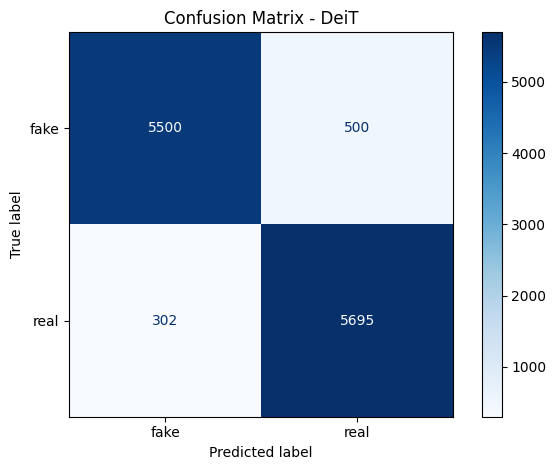

In [6]:
# Print out full classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=["fake", "real"]))

# Confusion Matrix: shows correct/incorrect predictions for each class
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["fake", "real"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - DeiT")
plt.tight_layout()
plt.show()


## Graphs and Additional Reports

You may re-run the classification report or confusion matrix here if needed (for example, for display as a DataFrame or in other formats).

Classification Report:
              precision    recall  f1-score   support

        fake       0.95      0.92      0.93      6000
        real       0.92      0.95      0.93      5997

    accuracy                           0.93     11997
   macro avg       0.93      0.93      0.93     11997
weighted avg       0.93      0.93      0.93     11997



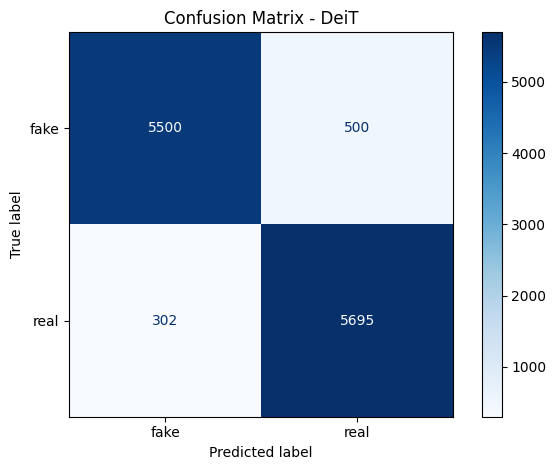

In [7]:
# Optional: print again for notebook display
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=["fake", "real"]))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["fake", "real"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - DeiT")
plt.tight_layout()
plt.show()


## Confusion Matrix and ROC Curve

Plot the ROC curve to evaluate the model's ability to discriminate between classes at different thresholds. The AUC (Area Under Curve) is a summary metric for model ranking ability.

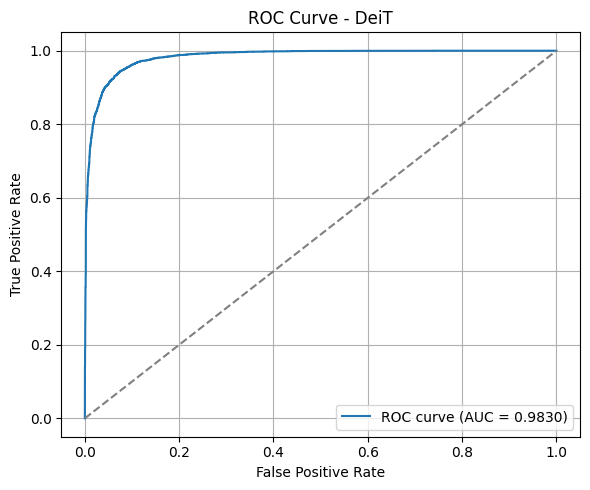

In [8]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_true, probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - DeiT")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Training Curves: Loss and Accuracy per Epoch

Load training and validation loss/accuracy curves from the metrics JSON file saved during training. These plots help diagnose overfitting, learning dynamics, and early stopping behavior.

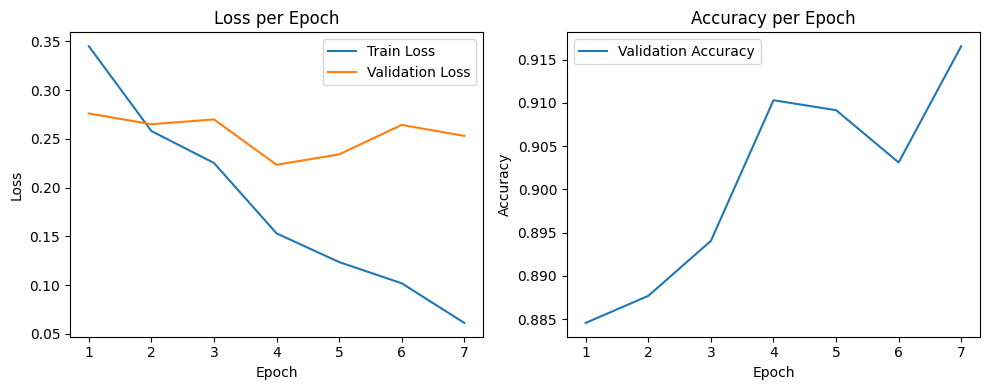

In [9]:
if os.path.exists(METRICS_PATH):
    with open(METRICS_PATH, 'r') as f:
        metrics = json.load(f)

    epochs = range(1, len(metrics['train_loss']) + 1)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, metrics['train_loss'], label='Train Loss')
    plt.plot(epochs, metrics['val_loss'], label='Validation Loss')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Loss per Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, metrics['val_acc'], label='Validation Accuracy')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Accuracy per Epoch")
    plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("Warning: Metrics file not found.")
